In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import tarfile
import os
import missingno as msno
import random
from sklearn.preprocessing import StandardScaler

In [36]:
file_path = '../data/1_raw_data.csv'
data = pd.read_csv(file_path, sep=';')
data.head()

,chanvre 5,chanvre 15,bambou 5,bambou 15,lin 5,lin 6,lin 15,miscanthus 5,miscanthus 15,ch.antif.,...,Days,Slump (mm),Air occluded (%),Volumic mass (kg/m3),FS (Mpa),CS (Mpa),Aspect ratio (L/D) soft fibers,Aspect ratio (L/D) rigid fibers,Absorption coefficient t=2880s soft fibers,Absorption coefficient t=2880s rigid fibers
0,"0,4",0,0,0,0,0,0,0,0,0,...,1,430,3.7,2.2287,2.79,11.36,154,0,135.27,0
1,0,"0,4",0,0,0,0,0,0,0,0,...,1,455,3.6,2.2198,3.13,10,308,0,135.47,0
2,0,0,"0,4",0,0,0,0,0,0,0,...,1,450,3.2,2.2366,2.43,8.69,0,17,0.00,98.93
3,0,0,0,"0,4",0,0,0,0,0,0,...,1,450,3.3,2.2312,2.82,9.17,0,33,0.00,89.7
4,0,0,0,0,"0,4",0,0,0,0,0,...,1,417.5,3.6,2.2117,2.56,7.11,167,0,155.27,0


In [37]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 21 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   chanvre 5                                    384 non-null    str    
 1   chanvre 15                                   384 non-null    str    
 2   bambou 5                                     384 non-null    str    
 3   bambou 15                                    384 non-null    str    
 4   lin 5                                        384 non-null    str    
 5   lin 6                                        384 non-null    str    
 6   lin 15                                       384 non-null    str    
 7   miscanthus 5                                 384 non-null    str    
 8   miscanthus 15                                384 non-null    str    
 9   ch.antif.                                    384 non-null    str    
 10  ch.strux     

In [38]:
data.describe()

,Days,Aspect ratio (L/D) soft fibers,Aspect ratio (L/D) rigid fibers,Absorption coefficient t=2880s soft fibers
count,384.000000,384.00000,384.000000,384.000000
mean,31.500000,163.75000,36.864583,87.281667
std,35.277342,167.65232,77.673834,71.146628
min,1.000000,0.00000,0.000000,0.000000
25%,5.500000,0.00000,0.000000,0.000000
50%,17.500000,154.00000,23.000000,135.270000
75%,43.500000,167.00000,33.000000,155.270000
max,90.000000,636.00000,333.000000,155.270000


# 2. Data Cleaning

## 2.1 Missing Values

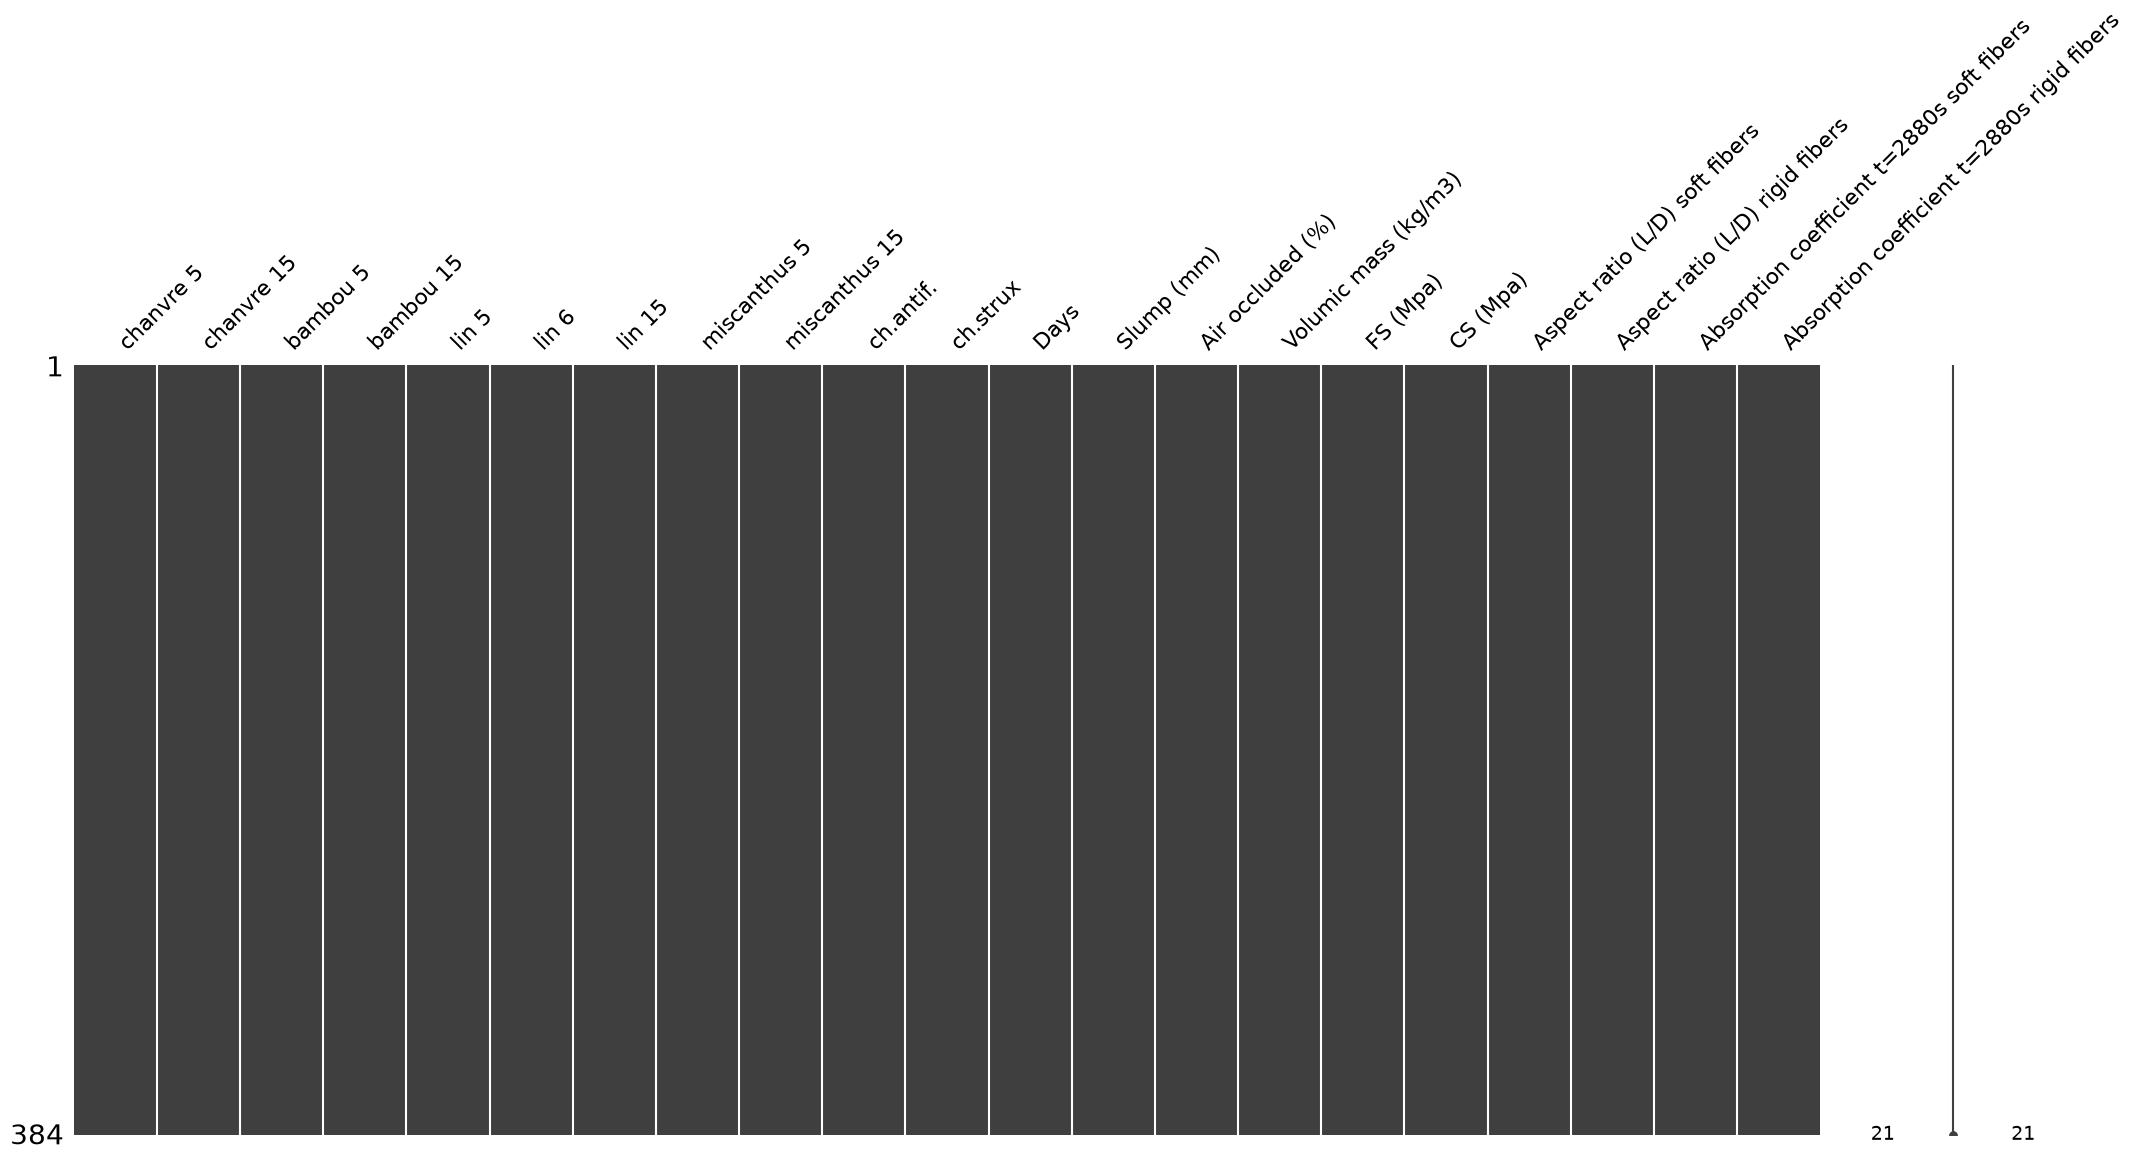

In [39]:
# Visualize missing data
msno.matrix(data)
plt.show()

In [40]:
def show_metric(data, column):
    print("=" * 50)
    print(f"{column:^50}")
    print("=" * 50)
    print(f"{'Données manquantes':<35} {data[column].isna().sum():>10}")
    print(f"{'% manquantes':<35} {round((data[column].isna().sum() / len(data)) * 100, 2):>9}%")
    print(f"{'Données disponibles':<35} {data[column].notna().sum():>10}")
    print(f"Lignes non alignées avec la colonne cible : {len([index for index, row in data.iterrows() if pd.isna(row[column]) and not pd.isna(row['Rc (MPa)'])])}")
    print("=" * 50)

show_metric(data, 'FS (Mpa)')

                     FS (Mpa)                     
Données manquantes                           0
% manquantes                              0.0%
Données disponibles                        384
Lignes non alignées avec la colonne cible : 0


<p style="color: grey;">
The datset has no missing value for flexural strength (FS).
</p>

## 2.3 Categorical Values

<p>On convertit les valeurs catégoriels présentes en integer </p>

In [41]:

categorical_columns = data.select_dtypes(include=['object', 'string']).columns
for column in categorical_columns:
    data[column] = data[column].str.replace(',', '.')
    data[column] = pd.to_numeric(data[column])

In [42]:
data.info() 

<class 'pandas.DataFrame'>
RangeIndex: 384 entries, 0 to 383
Data columns (total 21 columns):
 #   Column                                       Non-Null Count  Dtype  
---  ------                                       --------------  -----  
 0   chanvre 5                                    384 non-null    float64
 1   chanvre 15                                   384 non-null    float64
 2   bambou 5                                     384 non-null    float64
 3   bambou 15                                    384 non-null    float64
 4   lin 5                                        384 non-null    float64
 5   lin 6                                        384 non-null    float64
 6   lin 15                                       384 non-null    float64
 7   miscanthus 5                                 384 non-null    float64
 8   miscanthus 15                                384 non-null    float64
 9   ch.antif.                                    384 non-null    float64
 10  ch.strux     

## 2.2 Contrôle de cohérence des données

In [43]:
cols_fibre = [c for c in data.columns if 'Type' in c or 'Dosage' in c or 'Aspect' in c]
print(data.loc[data['Aspect ratio (L/D) rigid fibers'] > 100, cols_fibre].drop_duplicates())


m = data['Aspect ratio (L/D) rigid fibers'] > 100
data.loc[m, 'Aspect ratio (L/D) rigid fibers'] = 0

   Aspect ratio (L/D) soft fibers  Aspect ratio (L/D) rigid fibers
6                             333                              333


## 2.3 Harmonisation des unités de mesure

In [44]:
col = 'Volumic mass (kg/m3)'
data.loc[data[col] < 100, col] *= 1000   # 2.13 -> 2130 kg/m3 ; les 2228.4 restent tels quels
print(data[col].describe())              # doit aller d'environ 2100 à 2250

#Les ouliers de masse volumique nous ont permis d'identifier des erreurs de saisie à 0, nous allons donc les supprimer : 

Mv0 = data['Volumic mass (kg/m3)'] == 0
print("Lignes masse vol. = 0 :", (data['Volumic mass (kg/m3)'] == 0).sum())
print(data.loc[Mv0].filter(like='Type').drop_duplicates())   # quelles fibres/formulations
#supprimer les lignes avec masse volumique = 0
data = data.loc[~Mv0]

count     384.000000
mean     2154.535417
std       229.677724
min         0.000000
25%      2140.000000
50%      2194.600000
75%      2226.025000
max      2245.500000
Name: Volumic mass (kg/m3), dtype: float64
Lignes masse vol. = 0 : 4
Empty DataFrame
Columns: []
Index: [296, 325, 354, 383]


In [45]:
print("Air = 0 :", (data['Air occluded (%)'] == 0).sum())

Air = 0 : 48


In [ ]:
# ============================================================
# NETTOYAGE COMPLÉMENTAIRE DU JEU DE DONNÉES
# (à placer après l'harmonisation des unités et la correction du L/D du lin 15)
# ============================================================

fib_cols = ['chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 'lin 5', 'lin 6', 'lin 15',
            'miscanthus 5', 'miscanthus 15', 'ch.antif.', 'ch.strux']
n0 = len(data)

# ------------------------------------------------------------
# 1. FIBRES SYNTHÉTIQUES (ch.antif., ch.strux)  →  À FAIRE
# ------------------------------------------------------------
# Pourquoi c'est nécessaire :
#  - L'étude porte sur les fibres VÉGÉTALES ; les synthétiques sont la référence
#    industrielle du programme FIBRABETON (Materials 2023), pas l'objet d'étude.
#  - Leur teneur en air n'a pas été mesurée (codée 0 dans le fichier) et leur masse
#    volumique est recopiée de celle du mortier sans fibre (2 245,5).
#    -> Les garder obligerait à inventer deux variables clés.

# Physical contrast: synthetic fibres do not absorb water (absorption coefficient = 0), 
# which could help the model better capture the effect of water absorption, a distinctive feature of vegetal fibres.
# Vegetal vs. synthetic comparison: including them would allow such a comparison, but this falls outside the research question of the present study.
synth = (data['ch.antif.'] > 0) | (data['ch.strux'] > 0)
print(f"[1] Synthétiques : {synth.sum()} lignes")
data = data[~synth]

# ------------------------------------------------------------
# 2. LIN 6 MONOFIBRE AUX CIBLES CONSTANTES  →  À FAIRE
# ------------------------------------------------------------
# Dans le jeu bifibre, le lin est codé "lin 6" : ces lignes sont valides et conservées.
# Seules les formulations MONOFIBRE lin 6 à 1,2 / 2 / 4 kg/m3 posent problème :
# FS = 4,66 et CS = 26,75 à tous les âges (1 à 90 j), ce qui est physiquement impossible.
mono_lin6 = (data['lin 6'] > 0) & (data[[c for c in fib_cols if c != 'lin 6']].sum(axis=1) == 0)
const = mono_lin6 & (data['FS (Mpa)'] == 4.66) & (data['CS (Mpa)'] == 26.75)
print(f"[2] Lin 6 monofibre à cibles constantes : {const.sum()} lignes")
data = data[~const]

# On ne retire que les colonnes synthétiques (lin 6 reste utilisée par les bifibres)
data = data.drop(columns=['ch.antif.', 'ch.strux'])
fib_cols = [c for c in fib_cols if c not in ('ch.antif.', 'ch.strux')]

# ------------------------------------------------------------
# 3. BIFIBRES AVEC CIBLES IDENTIQUES À 1 ET 7 JOURS  →  À FAIRE,
#    SAUF SI SERGIO A LES VRAIES VALEURS
# ------------------------------------------------------------
# Pourquoi c'est nécessaire :
#  - Pour 8 formulations bifibres, FS et CS sont strictement identiques à 1 et 7 jours.
#    Deux âges différents ne donnent jamais exactement le même résultat :
#    une des deux lignes a été recopiée, et on ne sait pas laquelle.
#  - On retire seulement ces deux âges ; les valeurs à 28 et 90 j sont conservées.
data['formulation_id'] = data[fib_cols].astype(str).agg('|'.join, axis=1)
early = data[data['Days'].isin([1, 7])]
dup = early.groupby('formulation_id').filter(
    lambda x: len(x) == 2 and x[['FS (Mpa)', 'CS (Mpa)']].nunique().eq(1).all())
print(f"[3] Bifibres 1 j = 7 j : {len(dup)} lignes ({dup['formulation_id'].nunique()} formulations)")
print(dup[fib_cols + ['Days', 'FS (Mpa)', 'CS (Mpa)']])
data = data.drop(index=dup.index).reset_index(drop=True)

# ------------------------------------------------------------
# BILAN
# ------------------------------------------------------------
print(f"\n{n0} -> {len(data)} observations, {data['formulation_id'].nunique()} formulations")
print(data.shape)   # attendu : (292, 20) -> 19 variables + formulation_id

[1] Synthétiques : 48 lignes
[2] Lin 6 monofibre à cibles constantes : 12 lignes
[3] Bifibres 1 j = 7 j : 16 lignes (8 formulations)
     chanvre 5  chanvre 15  bambou 5  bambou 15  lin 5  lin 6  lin 15  \
272        1.0         0.0       0.0        2.2    0.0    0.0     0.0   
273        1.0         0.0       0.0        0.0    0.0    0.0     0.0   
274        0.0         0.0       0.0        2.2    0.0    1.0     0.0   
275        0.0         0.0       0.0        0.0    0.0    1.0     0.0   
280        0.6         0.0       0.0        2.6    0.0    0.0     0.0   
281        0.6         0.0       0.0        0.0    0.0    0.0     0.0   
282        0.0         0.0       0.0        2.6    0.0    0.6     0.0   
283        0.0         0.0       0.0        0.0    0.0    0.6     0.0   
301        1.0         0.0       0.0        2.2    0.0    0.0     0.0   
302        1.0         0.0       0.0        0.0    0.0    0.0     0.0   
303        0.0         0.0       0.0        2.2    0.0    1.0   

## 2.4 Outliers

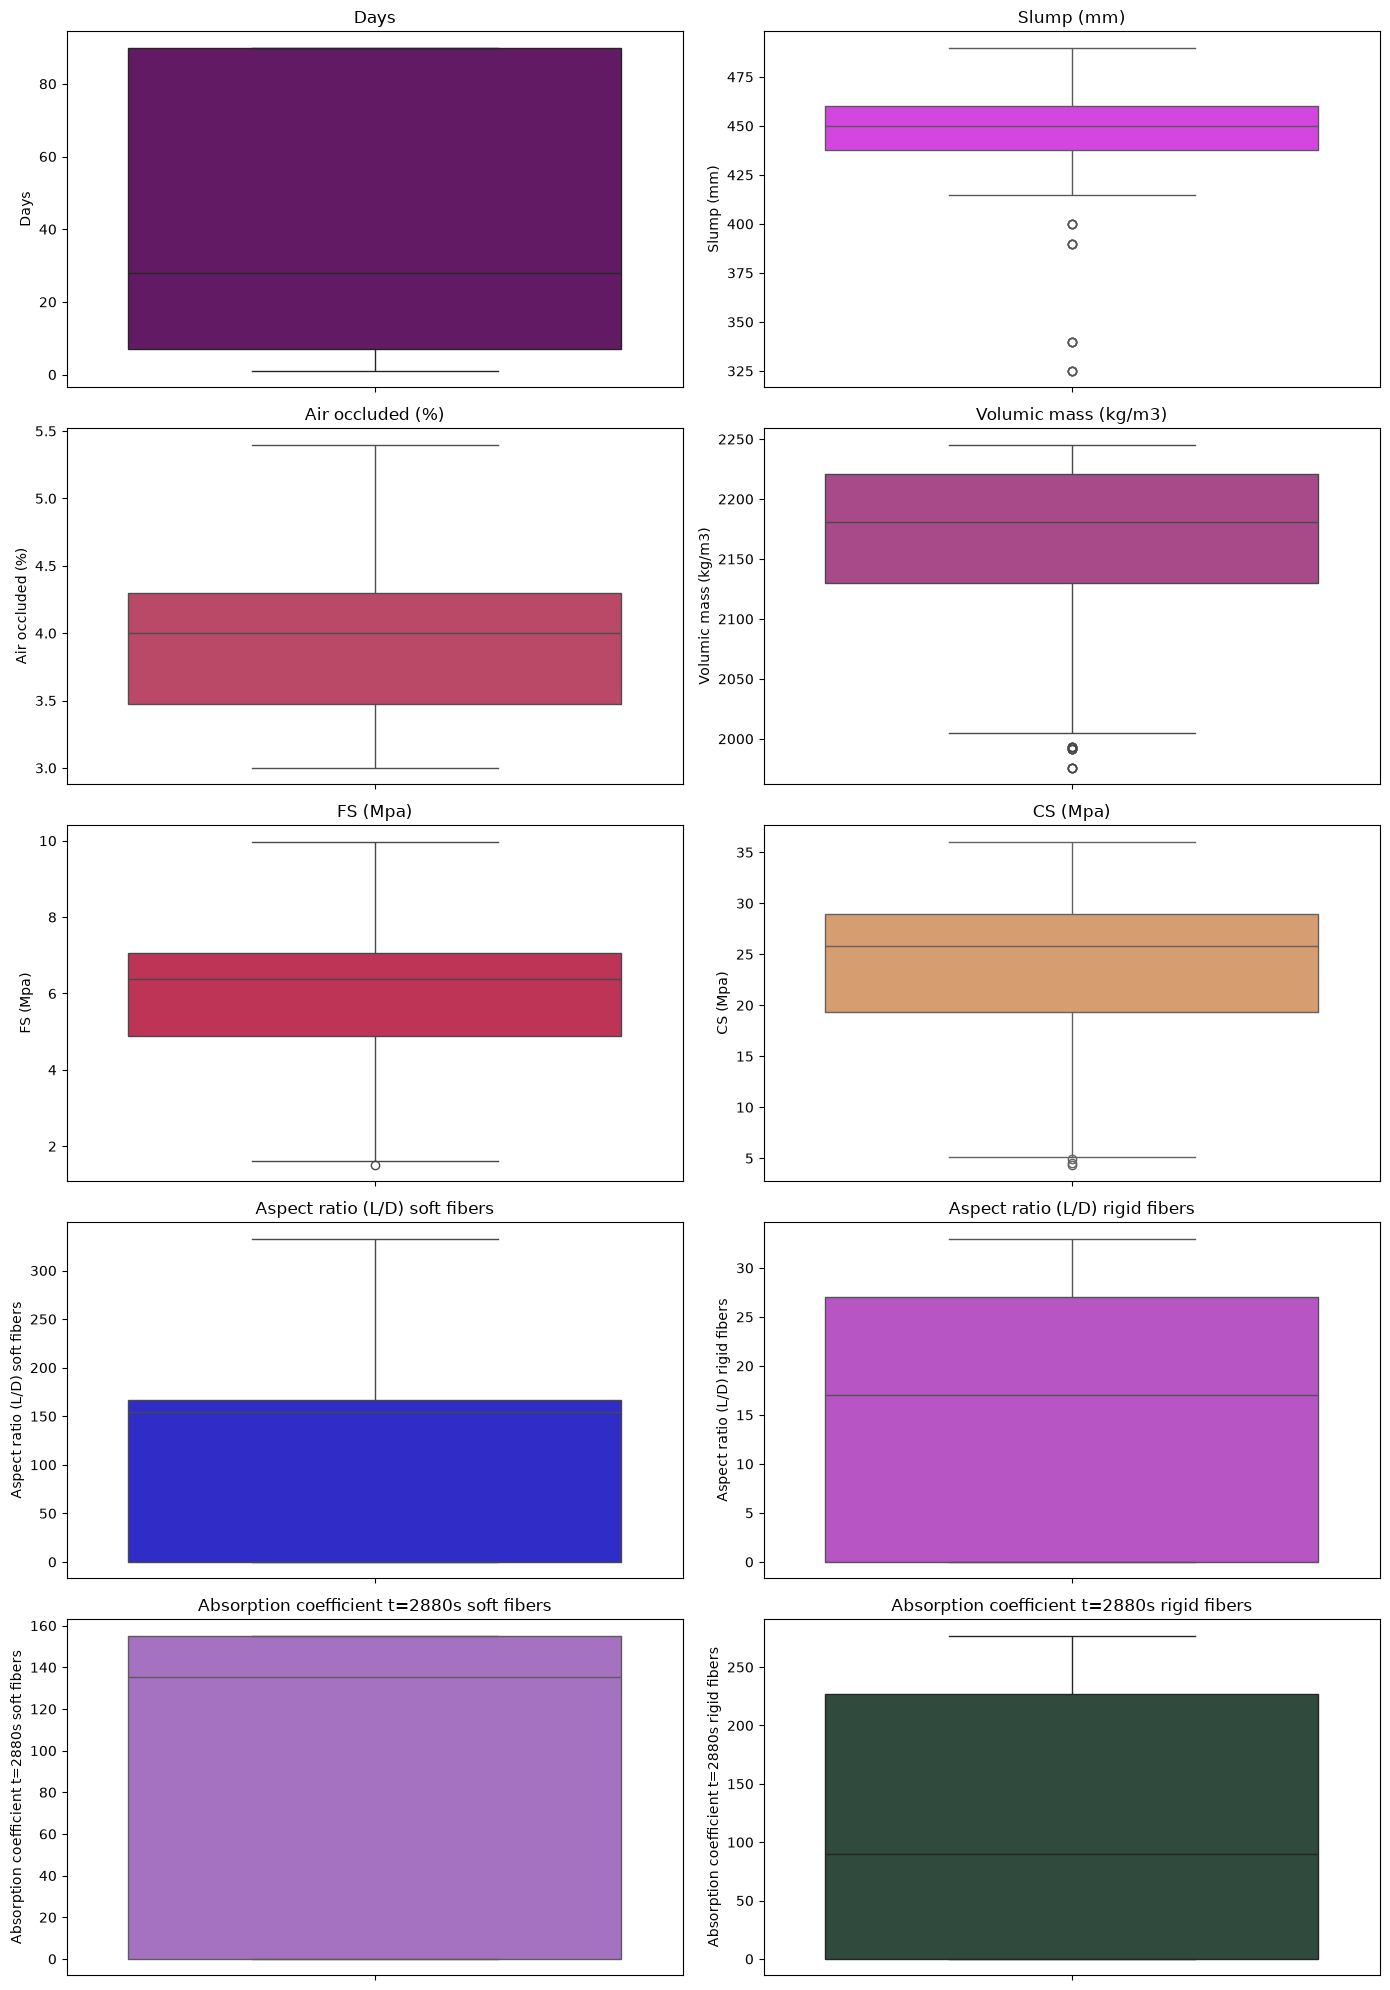

In [47]:
fiber_cols = ['chanvre 5', 'chanvre 15', 'bambou 5', 'bambou 15', 
              'lin 5', 'lin 6', 'lin 15', 'miscanthus 5', 'miscanthus 15',
              'ch.antif.', 'ch.strux']
#ne pas mettre les fiber_cols dans les colonnes numériques pour l'analyse statistique

numerical_columns = data.select_dtypes(include=['float64', 'int64']).columns
numerical_columns = [col for col in numerical_columns if col not in fiber_cols]
n = len(numerical_columns)
cols = 2
rows = (n + 1) // cols

fig, axes = plt.subplots(rows, cols, figsize=(14, rows * 4))
axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.boxplot(y=data[column], ax=axes[i], color=tuple(np.random.rand(3)))
    axes[i].set_title(column)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

<p>On ne supprime pas les valeurs aberrantes du dataset car elles sont normal et correspondent à de réel valeurs importantes pour notre études</p>

## 3. CSV Export

In [48]:
#export en csv 
data.to_csv('../data/2_cleaned_data.csv', index=False)